# Evidencia clase 29/10/26 — FIR por ventanas vs IIR

Retomo la plantilla pasabajos de la guía del 28/10 para el ECG ($f_s = 1000$ Hz) y comparo el Butterworth contra tres FIR diseñados con `sig.firwin2` usando distintas ventanas: **rectangular (boxcar)**, **Hamming** y **Blackman**.

Plantilla:
- Banda pasante: $0$ a $w_p = 35$ Hz, atenuación máxima $G_{pass} = 3$ dB
- Banda de rechazo: desde $w_s = 50$ Hz, atenuación mínima $G_{stop} = 40$ dB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle

fs_ecg = 1000 # Hz

## Importo la señal

In [2]:
print(sio.whosmat('../Extra/TS5/ECG_TP4.mat'))
mat_struct = sio.loadmat('../Extra/TS5/ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

[('ecg_lead', (1129116, 1), 'double'), ('qrs_pattern1', (113, 1), 'double'), ('heartbeat_pattern1', (411, 1), 'double'), ('heartbeat_pattern2', (441, 1), 'double'), ('qrs_detections', (1903, 1), 'double')]


## Diseño de los filtros IIR

Los IIR se van a aplicar con `sosfiltfilt` (ida y vuelta): la señal pasa **dos veces** por el filtro, así que el módulo efectivo es $|H|^2$ y las atenuaciones en dB se duplican. Por eso se **predistorsiona** la plantilla diseñando con $G_{pass}/2$ y $G_{stop}/2$: después del filtrado bidireccional se obtienen los 3 dB y 40 dB pedidos.

In [3]:
wp = 35 #[Hz]
ws = 50 #[Hz]

Gpass = 3
Gstop = 40
ripple = Gpass
att = Gstop

# predist por filt filt
sos_butt = sig.iirdesign(wp, ws, Gpass/2, Gstop/2, ftype='butter', fs = fs_ecg, output = 'sos')
sos_cheby2 = sig.iirdesign(wp, ws, Gpass/2, Gstop/2, ftype='cheby2', fs = fs_ecg, output = 'sos')
sos_cauer = sig.iirdesign(wp, ws, Gpass/2, Gstop/2, ftype='cauer', fs = fs_ecg, output = 'sos')

for nombre, sos in [('butter', sos_butt), ('cheby2', sos_cheby2), ('cauer', sos_cauer)]:
    print(f'{nombre}: orden {2 * sos.shape[0]}')

butter: orden 8
cheby2: orden 4
cauer: orden 4


## Diseño de los filtros FIR

`firwin2` recibe los puntos de la respuesta deseada: ganancia 1 hasta el borde de paso y 0 desde el borde de rechazo (`wp + delta_w`) hasta Nyquist. La ventana define el compromiso entre ancho de transición y atenuación de los lóbulos laterales:

| Ventana | Lóbulo principal | 1er lóbulo lateral (ventana) |
|---|---|---|
| Rectangular (boxcar) | el más angosto | ≈ −13 dB |
| Hamming | intermedio | ≈ −43 dB |
| Blackman | el más ancho | ≈ −58 dB |

Como cada ventana ensancha distinto la transición, los bordes se corren a mano (`wp-2`, `wp+2`) para acercar el filtro a la plantilla. La rectangular usa más coeficientes para angostar la transición, pero eso no baja sus lóbulos laterales.

In [4]:
# FIR design
taps_win = 131
taps_win_box = 191
delta_w = 5

b_win_boxcar = sig.firwin2( taps_win_box, [0.0, wp-2, wp + delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window = 'boxcar', fs = fs_ecg)
b_win_hamming = sig.firwin2( taps_win,    [0.0, wp+2, wp + delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window = 'hamming', fs = fs_ecg)
b_win_blackman = sig.firwin2( taps_win,   [0.0, wp,   wp + delta_w, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window = 'blackman', fs = fs_ecg)

## Funciones para calcular y graficar la respuesta

In [5]:
y_min, y_max = -100, 5


def calc_freq_sos( sos ):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    resp_freq = sig.freqz_sos(sos, worN=8192, fs=fs_ecg)

    return resp_freq


def calc_freq_fir( bfir ):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    resp_freq = sig.freqz(bfir, 1, worN=8192, fs=fs_ecg)

    return resp_freq


def calc_resp( resp_freq, leg_str, fig_n_axes ):

    f, h = resp_freq

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label= leg_str )
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label= leg_str, linewidth=1.2)
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)


def plot_plantilla( fig_n_axes ):

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # Banda pasante: zona no permitida por debajo de -ripple
    rect_pasante = Rectangle(
        (0, y_min), wp, -ripple - y_min,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2 , label = 'Plantilla'
    )
    ax_mod.add_patch(rect_pasante)

    # Banda de rechazo: zona no permitida por encima de -att
    rect_rechazo = Rectangle(
        (ws, -att), fs_ecg / 2 - ws, y_max + att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax_mod.add_patch(rect_rechazo)

    for ax in (ax_mod, ax_fase):
        ax.axvline(wp, color='k', ls=':', lw=1)
        ax.axvline(ws, color='k', ls=':', lw=1)

    ax_mod.legend(loc='lower left', fontsize=8)


def graficar_todos():

    fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)

    # IIR: respuesta efectiva de sosfiltfilt -> |H|^2 y fase cero
    f, h = calc_freq_sos(sos_butt)
    calc_resp( (f, np.abs(h)**2), 'butter (filtfilt)', fig_n_axes )

    # FIR
    calc_resp( calc_freq_fir(b_win_boxcar), f'FIR boxcar {taps_win_box}', fig_n_axes )
    calc_resp( calc_freq_fir(b_win_hamming), f'FIR hamming {taps_win}', fig_n_axes )
    calc_resp( calc_freq_fir(b_win_blackman), f'FIR blackman {taps_win}', fig_n_axes )

    plot_plantilla(fig_n_axes)

    return fig_n_axes

## Respuesta de los filtros + plantilla

Para el Butterworth grafico la respuesta **efectiva con filtfilt**, $|H|^2$ con fase nula, que es la que tiene que cumplir la plantilla. Los FIR tienen fase lineal (rectas en el gráfico de fase, con saltos de $\pi$ en los ceros del módulo).

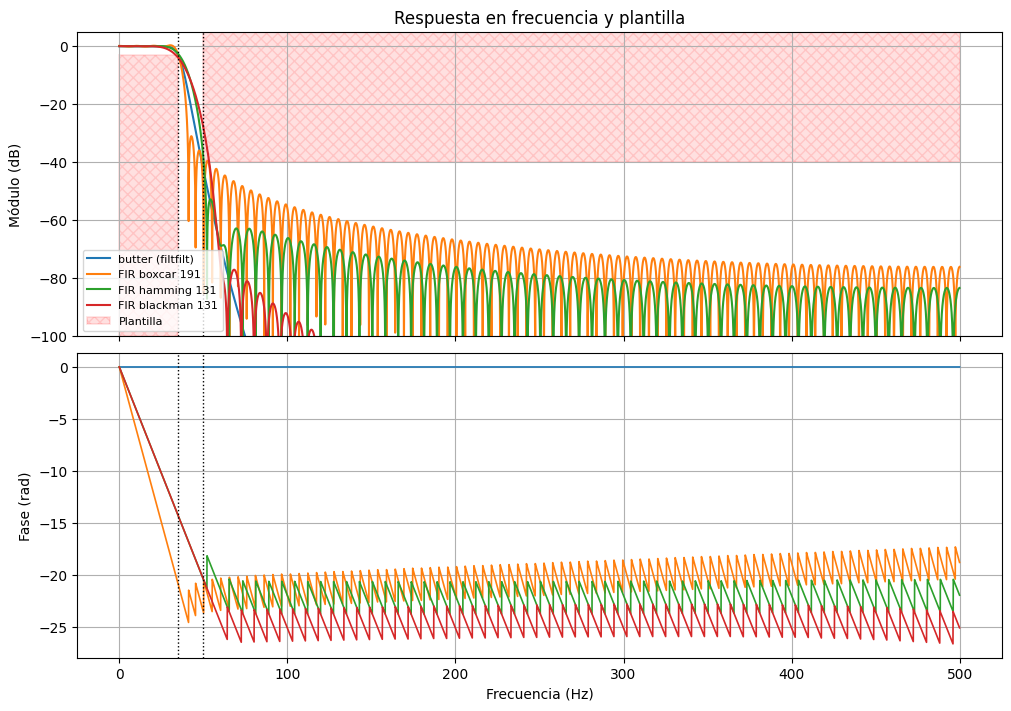

In [6]:
fig_n_axes = graficar_todos()
plt.show()

Zoom en la banda de transición:

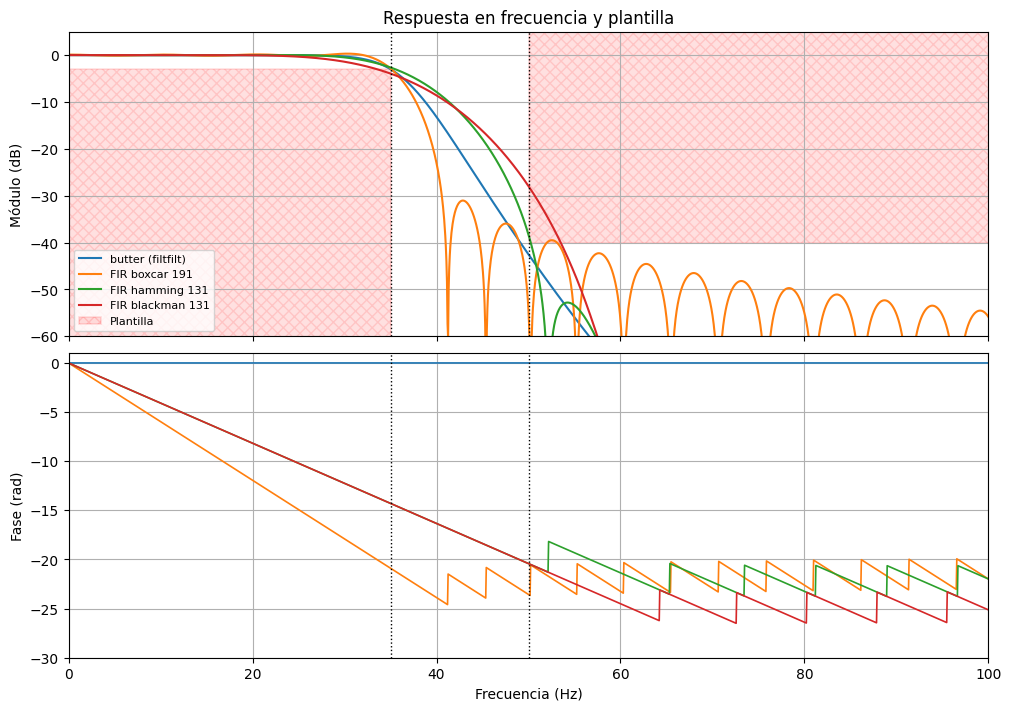

In [7]:
(fig, (ax_mod, ax_fase)) = graficar_todos()
ax_mod.set_xlim(0, 100)
ax_mod.set_ylim(-60, 5)
ax_fase.set_ylim(-30, 1)
plt.show()

Verifico numéricamente la plantilla en $w_p$ y el peor caso en toda la banda de rechazo ($f \geq w_s$):

In [8]:
resp = [('butter (filtfilt)', calc_freq_sos(sos_butt), True),
        (f'FIR boxcar {taps_win_box}', calc_freq_fir(b_win_boxcar), False),
        (f'FIR hamming {taps_win}', calc_freq_fir(b_win_hamming), False),
        (f'FIR blackman {taps_win}', calc_freq_fir(b_win_blackman), False)]

for nombre, (f, h), es_filtfilt in resp:
    h = np.abs(h)**2 if es_filtfilt else np.abs(h)
    mod_db = 20 * np.log10(np.maximum(h, 1e-12))
    en_wp = np.interp(wp, f, mod_db)
    peor_rechazo = mod_db[f >= ws].max()
    tol = 0.01  # dB, para no fallar por redondeo justo en el borde
    cumple = (en_wp >= -ripple - tol) and (peor_rechazo <= -att + tol)
    print(f'{nombre:20s} |H(wp)| = {en_wp:6.2f} dB   max en rechazo = {peor_rechazo:6.2f} dB   -> {"cumple" if cumple else "NO cumple"}')

butter (filtfilt)    |H(wp)| =  -3.00 dB   max en rechazo = -42.67 dB   -> cumple
FIR boxcar 191       |H(wp)| =  -2.86 dB   max en rechazo = -39.50 dB   -> NO cumple
FIR hamming 131      |H(wp)| =  -2.64 dB   max en rechazo = -38.66 dB   -> NO cumple
FIR blackman 131     |H(wp)| =  -3.94 dB   max en rechazo = -28.10 dB   -> NO cumple


## Respuesta al impulso de los IIR

Excito cada IIR con una delta y miro cuánto tarda en extinguirse $h(n)$ (normalizada por su máximo para comparar la forma). A diferencia de un FIR, cuya duración es la cantidad de coeficientes, la respuesta de un IIR es infinita, aunque en la práctica decae en unas ~200 muestras (200 ms).

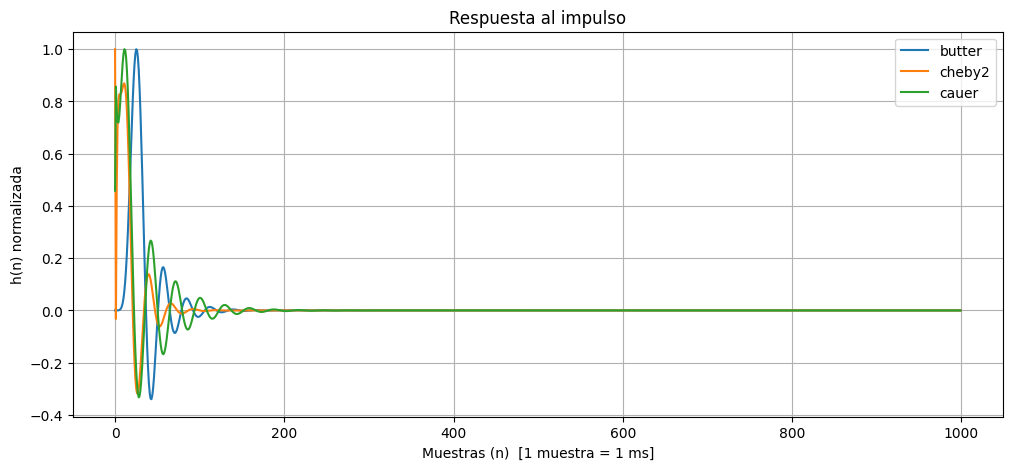

In [9]:
delta = np.zeros(1000)
delta[0] = 1

plt.figure(figsize=(12, 5))
for nombre, sos in [('butter', sos_butt), ('cheby2', sos_cheby2), ('cauer', sos_cauer)]:
    h_imp = sig.sosfilt(sos, delta)
    plt.plot(h_imp / np.abs(h_imp).max(), label=nombre)

plt.title('Respuesta al impulso')
plt.xlabel('Muestras (n)  [1 muestra = 1 ms]')
plt.ylabel('h(n) normalizada')
plt.grid(True)
plt.legend()
plt.show()

## Diseño de un FIR de 190 coeficientes que cumpla la plantilla

Con 131 coeficientes ninguna ventana alcanzaba. Subo a **190 coeficientes** y, en lugar de poner el borde de la transición deseada en $w_p$, la **centro entre $w_p$ y $w_s$** ($\frac{35+50}{2} = 42.5$ Hz): `firwin2` pide ganancia 1 hasta 42 Hz y 0 desde 43 Hz. La ventana ensancha esa transición ideal hacia ambos lados, y al quedar centrada se reparte entre la banda de paso y la de rechazo sin invadir ninguna.

Comparo dos ventanas con el mismo largo: **Hamming** y **Hann**.

Nota: con una cantidad **par** de coeficientes el FIR es de tipo II (simétrico, sigue teniendo fase lineal), pero su retardo $(190-1)/2 = 94.5$ muestras no es entero. Al compensarlo con `(N-1)//2 = 94` queda medio milisegundo de desfasaje, que en el ECG no se nota.

In [10]:
taps_190 = 190

b_win_hamm_190 = sig.firwin2( taps_190, [0.0, 42, 43, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window = 'hamming', fs = fs_ecg)
b_win_hann_190 = sig.firwin2( taps_190, [0.0, 42, 43, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window = 'hann', fs = fs_ecg)

for nombre, b in [(f'FIR hamming {taps_190}', b_win_hamm_190), (f'FIR hann {taps_190}', b_win_hann_190)]:
    f, h = calc_freq_fir(b)
    mod_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    en_wp = np.interp(wp, f, mod_db)
    peor_rechazo = mod_db[f >= ws].max()
    cumple = (en_wp >= -ripple) and (peor_rechazo <= -att)
    print(f'{nombre:20s} |H(wp)| = {en_wp:6.2f} dB   max en rechazo = {peor_rechazo:6.2f} dB   -> {"cumple" if cumple else "NO cumple"}')

FIR hamming 190      |H(wp)| =  -0.19 dB   max en rechazo = -41.86 dB   -> cumple
FIR hann 190         |H(wp)| =  -0.25 dB   max en rechazo = -40.59 dB   -> cumple


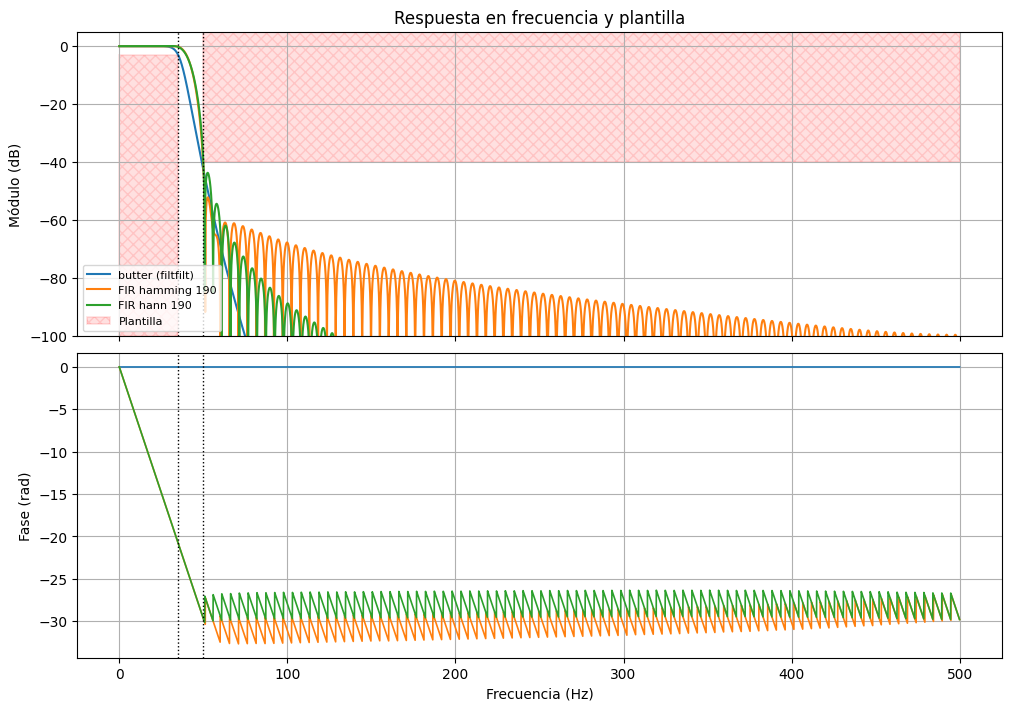

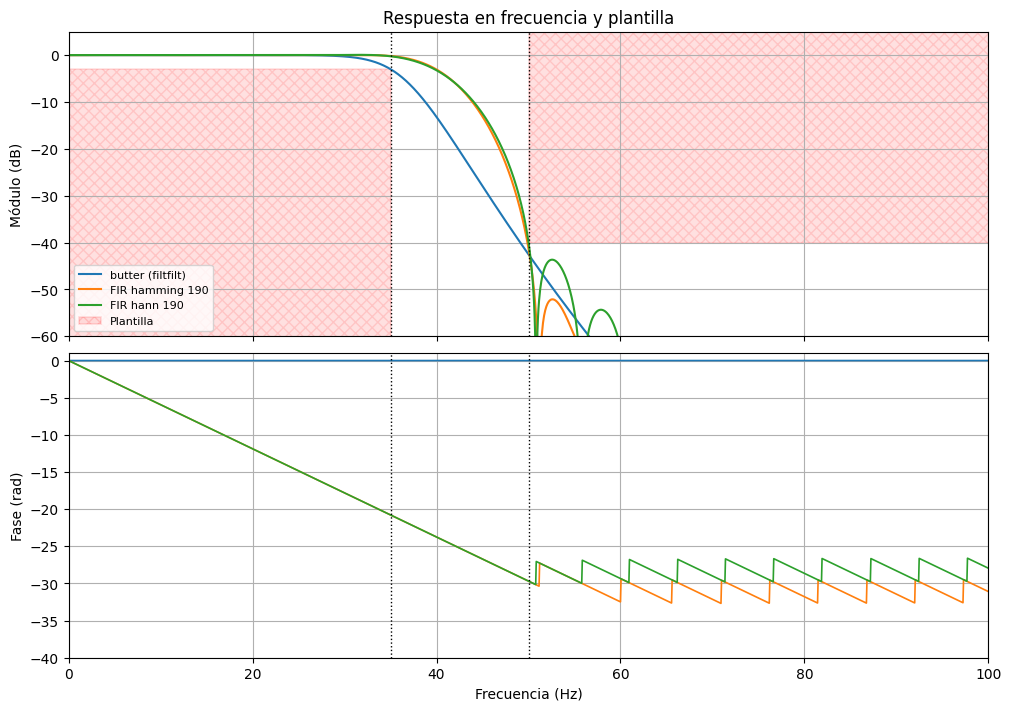

In [11]:
for zoom in (False, True):
    fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)

    f, h = calc_freq_sos(sos_butt)
    calc_resp( (f, np.abs(h)**2), 'butter (filtfilt)', fig_n_axes )
    calc_resp( calc_freq_fir(b_win_hamm_190), f'FIR hamming {taps_190}', fig_n_axes )
    calc_resp( calc_freq_fir(b_win_hann_190), f'FIR hann {taps_190}', fig_n_axes )
    plot_plantilla(fig_n_axes)

    (fig, (ax_mod, ax_fase)) = fig_n_axes
    if zoom:
        ax_mod.set_xlim(0, 100)
        ax_mod.set_ylim(-60, 5)
        ax_fase.set_ylim(-40, 1)
    plt.show()

## Aplicación de los filtros al ECG

- IIR: `sosfiltfilt` (fase cero, no hace falta compensar nada).
- FIR: `lfilter` (causal). Como tienen fase lineal, la salida es la entrada filtrada **retrasada** $(N_{taps}-1)/2$ muestras; al graficar se compensa indexando `y[zoom_region + demora]`.

In [12]:
ecg_filt_butt = sig.sosfiltfilt(sos_butt, ecg_one_lead)

ecg_filt_winbox = sig.lfilter( b_win_boxcar, 1, ecg_one_lead )
ecg_filt_winhamm = sig.lfilter( b_win_hamming, 1, ecg_one_lead )
ecg_filt_hamm_190 = sig.lfilter( b_win_hamm_190, 1, ecg_one_lead )
ecg_filt_hann_190 = sig.lfilter( b_win_hann_190, 1, ecg_one_lead )

demora_box = (b_win_boxcar.shape[0] -1)//2
demora_hamm = (b_win_hamming.shape[0] -1)//2
demora_190 = (taps_190 -1)//2

cant_muestras = ecg_one_lead.shape[0]


def graficar_regiones( regs_interes ):

    for ii in regs_interes:

        # intervalo limitado de 0 a cant_muestras (dejo lugar para la demora de los FIR)
        zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras - demora_190, ii[1]]), dtype='uint')

        plt.figure(figsize=(12, 5))
        plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
        plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butter')
        plt.plot(zoom_region, ecg_filt_winbox[zoom_region + demora_box], label='WinBox')
        plt.plot(zoom_region, ecg_filt_winhamm[zoom_region + demora_hamm], label='WinHam')
        plt.plot(zoom_region, ecg_filt_hamm_190[zoom_region + demora_190], label='WinHam 190')
        plt.plot(zoom_region, ecg_filt_hann_190[zoom_region + demora_190], label='WinHan 190')

        plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
        plt.ylabel('Adimensional')
        plt.xlabel('Muestras (#)')

        axes_hdl = plt.gca()
        axes_hdl.legend()
        axes_hdl.set_yticks(())

        plt.show()

### Regiones de interés sin ruido

En los latidos limpios todos los filtros deberían dejar la señal prácticamente igual: el pasabajos no tiene que deformar el QRS ni las ondas P y T.

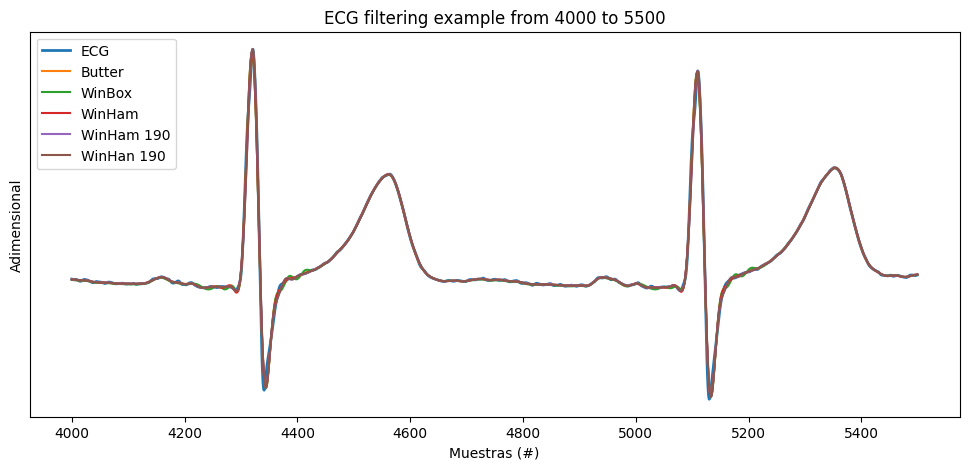

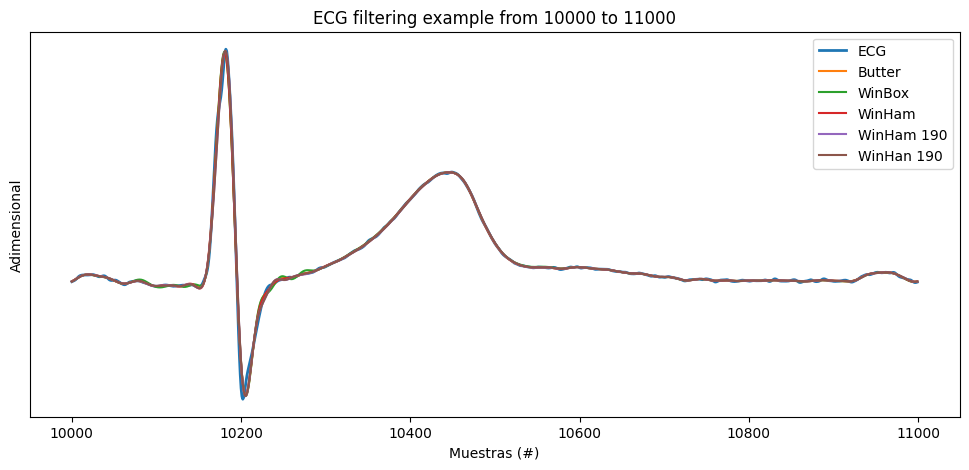

In [13]:
regs_interes = (
        [4000, 5500], # muestras
        [10000, 11000], # muestras
        )

graficar_regiones(regs_interes)

### Regiones de interés con ruido

Zonas del registro con ruido de alta frecuencia y movimiento de línea de base. El pasabajos limpia el ruido de alta frecuencia; el movimiento de línea de base (baja frecuencia) pasa intacto porque cae dentro de la banda de paso.

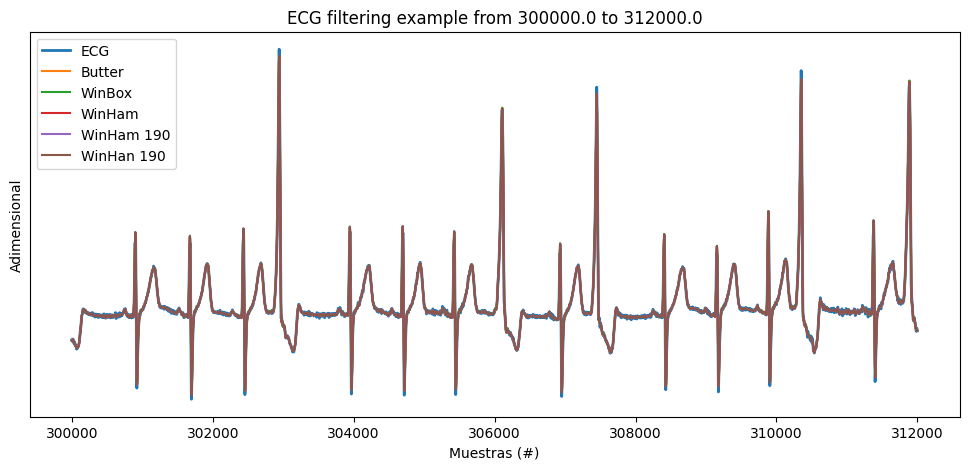

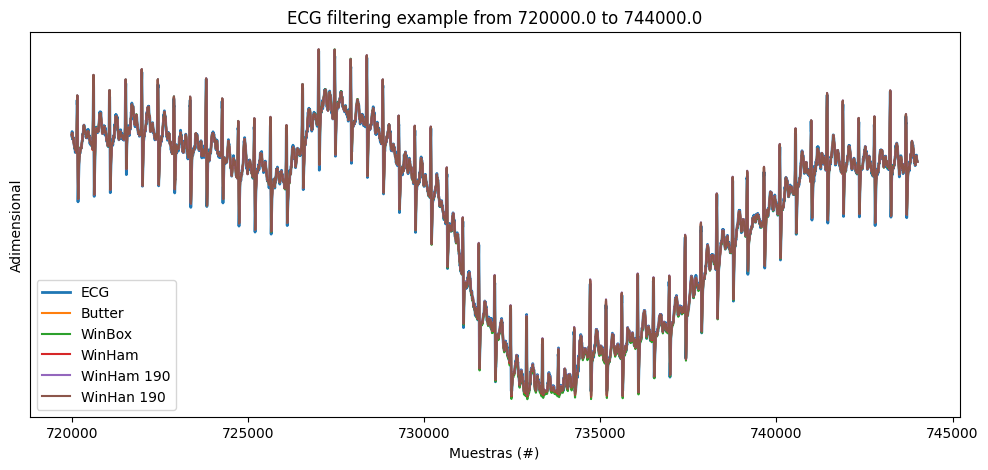

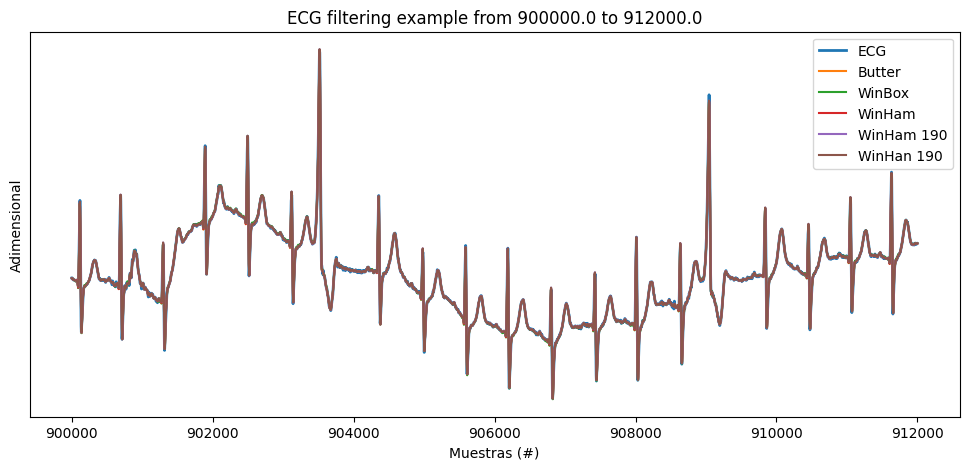

In [14]:
regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

graficar_regiones(regs_interes)

## Conclusiones

- **Predistorsión para filtfilt:** diseñando el Butterworth con $G_{pass}/2 = 1.5$ dB y $G_{stop}/2 = 20$ dB, la respuesta efectiva $|H|^2$ queda justo en $-3$ dB en $w_p$ y por debajo de $-40$ dB en el rechazo, y sin distorsión de fase. Con la plantilla a la mitad, el cheby2 y el cauer salen de orden 4 y el Butterworth de orden 8.
- **Ninguno de los tres FIR cumple estrictamente la plantilla** con estos parámetros: la transición de 15 Hz es muy angosta para 131/191 coeficientes.
  - **Boxcar (191):** tiene la transición más abrupta, pero sus lóbulos laterales son altos (≈ −39.5 dB, apenas fuera de la plantilla) y casi no bajan al alejarse de la banda de paso.
  - **Hamming (131):** buen compromiso; queda ≈ 1.3 dB por encima del límite cerca de $w_s$, y lejos de la transición atenúa mucho más que la boxcar.
  - **Blackman (131):** es la que más atenúa lejos de la banda (lóbulos muy bajos), pero su lóbulo principal es el más ancho: en $w_s$ solo llega a ≈ −28 dB y además cae casi 4 dB en $w_p$. Para cumplir necesitaría más coeficientes.
- La elección de la ventana es un compromiso entre **ancho de transición** (boxcar < Hamming < Blackman) y **atenuación en la banda de rechazo** (boxcar < Hamming < Blackman). Los bordes de `firwin2` (`wp-2`, `wp+2`) se ajustan a mano para acomodar la respuesta.
- **FIR de 190 coeficientes:** centrando la transición de `firwin2` en 42–43 Hz, la Hamming cumple la plantilla con margen (≈ −0.2 dB en $w_p$, ≈ −41.9 dB en el peor punto del rechazo) y la Hann la cumple más justo (≈ −40.6 dB). La clave no fue solo agregar coeficientes: también hubo que ubicar bien los bordes de la respuesta deseada.
- **En el ECG:** en los latidos limpios todos los filtros prácticamente coinciden con la señal original; la boxcar, por sus lóbulos altos, deja algunas oscilaciones (ringing) cerca del QRS. En las zonas ruidosas se elimina el ruido de alta frecuencia, pero el movimiento de línea de base no, porque está dentro de la banda de paso: para eso hace falta un pasaaltos.
- **IIR vs FIR:** el IIR cumple la plantilla con orden 8 (4 secciones SOS), mientras que los FIR necesitan más de 100 coeficientes. A cambio, los FIR tienen fase lineal y su retardo constante, $(N_{taps}-1)/2$ muestras, se compensa fácilmente; el IIR necesita `filtfilt` (no causal) para tener fase cero.